# Statistical analysis of Nifty 500 standalone quarterly financial results
**Puneet Jaiswal | Walsh College | QM640: Data Analytics Capstone**  
Instructor: Abhay Poddar | Notebook prepared: October 20, 2026

## Purpose and  scope
This notebook supports the interim report for *Machine Learning-Based Prediction of Next-Quarter Corporate Profitability*. It preserves the original synopsis research questions while replacing the proposed 100-company sample with available companies from the selected Nifty 500 universe. The supplied extract contains 426 companies and 3,824 records, June 2022–December 2024. It uses standalone results only. It does not establish historical index membership or represent all Indian listed companies.

The original 2020–2025 window and consolidated preference are superseded by the supplied extract. Membership date, extraction date, selection exclusions and unit normalization must be confirmed from the ingestion pipeline. Current index selection may introduce survivorship bias.

**Run:** Keep the supplied CSV beside this notebook and run all cells in order. Dependencies: pandas, numpy, matplotlib, scipy, scikit-learn, IPython. A fixed seed makes results reproducible. Outputs are saved to `analysis_outputs/`.

This is the analytical notebook requested, not the PDF-only interim-report submission. No separate report template was supplied. Model results below are exploratory development results; confirm the protocol before final evaluation.

In [ ]:
from pathlib import Path
import hashlib, platform, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import sklearn
SEED = 640
rng = np.random.default_rng(SEED)
DATA_PATH = Path('/content/Nifty500_Standalone_Quarterly_Available.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('outputs/nifty500_analysis') / DATA_PATH.name
OUTPUT = DATA_PATH.parent / 'analysis_outputs'
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True, 'figure.dpi': 110})
raw = pd.read_csv(DATA_PATH, low_memory=False)
provenance = {'csv_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
              'rows': len(raw), 'columns': len(raw.columns), 'python': platform.python_version(),
              'pandas': pd.__version__, 'numpy': np.__version__, 'sklearn': sklearn.__version__}
display(pd.Series(provenance, name='Reproducibility'))
(OUTPUT/'provenance.json').write_text(json.dumps(provenance, indent=2))
display(raw.head(3))

,Reproducibility
csv_sha256,052f8a0cad4fc10f4c8106bfe2b086fc89423057eb233f...
rows,3824
columns,142
python,3.13.16
pandas,2.2.3
numpy,2.1.3
sklearn,1.6.1


,SOURCE_FILE,FILING_FORMAT,FORMAT_EVIDENCE,CONTEXT_ID,CONTEXT_DEFINED,ENTITY_IDENTIFIER,PERIOD_START,PERIOD_END,INSTANT,DIMENSIONS,...,GROSS_NPA_UNIT,GROSS_NPA_DECIMALS,NET_NPA,NET_NPA_TAG,NET_NPA_UNIT,NET_NPA_DECIMALS,_date,_start,_quarter,_complete
0,INDAS_911979_5911_03122022152749_WEB.xml,INDAS,filename=INDAS; content=INDAS_OR_NBFC,OneD,True,539083,2022-07-01,2022-09-30,NaN,[],...,NaN,NaN,NaN,NaN,NaN,NaN,2022-09-30,2022-07-01,2022Q3,True
1,INDAS_899560_4797_25112022123204_WEB.xml,INDAS,filename=INDAS; content=INDAS_OR_NBFC,OneD,True,500550,2022-07-01,2022-09-30,NaN,[],...,NaN,NaN,NaN,NaN,NaN,NaN,2022-09-30,2022-07-01,2022Q3,True
2,INDAS_881082_6646_16112022145915_WEB.xml,INDAS,filename=INDAS; content=INDAS_OR_NBFC,OneD,True,543573,2022-07-01,2022-09-30,NaN,[],...,NaN,NaN,NaN,NaN,NaN,NaN,2022-09-30,2022-07-01,2022Q3,True


## Research questions and analysis plan
1. **RQ1:** Can historical quarterly results predict next-quarter PAT growth? Compare future-period errors with zero-growth and historical-median baselines.
2. **RQ2:** Which historical variables contribute to prediction? Examine correlations and validation permutation importance. Importance is not a significance test or causal effect.
3. **RQ3:** Which regression model predicts most accurately? Compare linear regression, ridge, random forest and gradient boosting on identical observations and chronological periods.
4. **RQ4:** Do derived features improve accuracy? Compare reported-only and enhanced features using the same ridge algorithm and evaluation rows.

PAT growth is continuous: `100 × (PAT[t+1] − PAT[t]) / abs(PAT[t])`. Zero denominators are excluded. Negative base PAT is retained and flagged; the quantity measures change relative to the magnitude of base profit, not a conventional positive-base growth rate. Near-zero denominators can cause extreme targets. A fixed floor is configurable below; the default excludes only zero. No target winsorization is applied.

The synopsis's overall regression F-test and predictor significance claims require a separate dependence-aware inferential specification. This notebook does not equate prediction scores or feature importance with rejection of those hypotheses.

In [ ]:
financial = ['PAT','REVENUE','TOTAL_INCOME','OTHER_INCOME','PROFIT_BEFORE_TAX',
             'TAX_EXPENSE','EXPENSES','FINANCE_COSTS','EPS_BASIC','EPS_DILUTED',
             'ASSETS','LIABILITIES','EQUITY','BORROWINGS']
dictionary = pd.DataFrame({'field': raw.columns, 'dtype': raw.dtypes.astype(str).values,
                           'nonmissing': raw.notna().sum().values,
                           'missing_pct': 100*raw.isna().mean().values})
dictionary.to_csv(OUTPUT/'source_data_dictionary.csv',index=False)
display(dictionary[dictionary.field.isin(financial + ['COMPANY_KEY','INDEX_INDUSTRY','PERIOD_START','PERIOD_END','SOURCE_XBRL_URL'])])
display(raw[['FILING_FORMAT','REPORTING_CURRENCY','ROUNDING','PERIOD_KIND','STANDALONE_CONSOLIDATED']].value_counts(dropna=False).head(20))
display(raw[['SOURCE_XBRL_URL','PAT_TAG','PAT_UNIT','PAT_DECIMALS']].head(3))
print('Source URLs retained:', raw.SOURCE_XBRL_URL.notna().sum())

,field,dtype,nonmissing,missing_pct
6,PERIOD_START,object,3824,0.000000
7,PERIOD_END,object,3824,0.000000
24,PAT,float64,3824,0.000000
44,REVENUE,float64,3659,4.314854
48,TOTAL_INCOME,float64,3824,0.000000
52,OTHER_INCOME,float64,3824,0.000000
56,PROFIT_BEFORE_TAX,float64,3824,0.000000
60,TAX_EXPENSE,float64,3824,0.000000
64,EXPENSES,float64,3659,4.314854
68,FINANCE_COSTS,float64,3659,4.314854


FILING_FORMAT  REPORTING_CURRENCY  ROUNDING  PERIOD_KIND   STANDALONE_CONSOLIDATED
INDAS          INR                 Crores    quarter_like  Standalone                 1525
                                   Lakhs     quarter_like  Standalone                  912
                                   Millions  quarter_like  Standalone                  871
NBFC           INR                 Crores    quarter_like  Standalone                  258
BANKING        INR                 Lakhs     quarter_like  Standalone                  117
NBFC           INR                 Lakhs     quarter_like  Standalone                   49
BANKING        INR                 Crores    quarter_like  Standalone                   48
NBFC           INR                 Millions  quarter_like  Standalone                   44
Name: count, dtype: int64

,SOURCE_XBRL_URL,PAT_TAG,PAT_UNIT,PAT_DECIMALS
0,https://nsearchives.nseindia.com/corporate/xbr...,{http://www.bseindia.com/xbrl/fin/2020-03-31/i...,"{""denominator"": [], ""numerator"": [""{http://www...",-5
1,https://nsearchives.nseindia.com/corporate/xbr...,{http://www.bseindia.com/xbrl/fin/2020-03-31/i...,"{""denominator"": [], ""numerator"": [""{http://www...",-6
2,https://nsearchives.nseindia.com/corporate/xbr...,{http://www.bseindia.com/xbrl/fin/2020-03-31/i...,"{""denominator"": [], ""numerator"": [""{http://www...",-4


Source URLs retained: 3824


## Data quality and preprocessing
 Monetary magnitudes appear stored in INR base units, while `ROUNDING` describes filing display conventions. **Do not multiply again by lakhs/millions.** Check source tags, units and representative XML filings against extraction code before making currency-scale claims. Plots below use input monetary units and explicitly label them.

Preserve raw values. Remove exact duplicate records only. Quarantine ambiguous duplicate company-period records rather than selecting a filing arbitrarily. Retain verified standalone, INR, strict quarter candidates with 80–100-day periods and no reported dimensions. Missing financial predictors remain missing until training-only median imputation. Missing targets are never imputed. Outliers are flagged, not deleted merely because they are large. Balance-sheet fields may be structurally missing and are not automatically filled forward.

In [ ]:
d = raw.drop_duplicates().copy()
for col in ['PERIOD_START','PERIOD_END']:
    d[col] = pd.to_datetime(d[col], errors='coerce')
for col in financial:
    d[col] = pd.to_numeric(d[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
def true_flag(s):
    return s.astype(str).str.lower().eq('true')
d['duration'] = (d.PERIOD_END-d.PERIOD_START).dt.days+1
d['q'] = d.PERIOD_END.dt.to_period('Q')
ambiguous = d.duplicated(['COMPANY_KEY','PERIOD_START','PERIOD_END'],keep=False)
eligible = (d.COMPANY_KEY.notna() & d.q.notna() & d.duration.between(80,100)
            & d.STANDALONE_CONSOLIDATED.eq('Standalone') & d.REPORTING_CURRENCY.eq('INR')
            & true_flag(d.STRICT_QUARTER_CANDIDATE) & d.DIMENSIONS.fillna('[]').eq('[]') & ~ambiguous)
audit = pd.Series({'raw_rows':len(raw),'exact_duplicates_removed':len(raw)-len(d),
                   'ambiguous_period_rows':int(ambiguous.sum()),'eligible_rows':int(eligible.sum()),
                   'excluded_rows_after_exact_dedup':int((~eligible).sum())})
d.loc[~eligible].to_csv(OUTPUT/'excluded_rows.csv',index=False)
d = d.loc[eligible].sort_values(['COMPANY_KEY','PERIOD_END']).copy()
assert not d.duplicated(['COMPANY_KEY','q']).any(), 'Review multiple records per calendar quarter'
display(audit)
display(d.groupby('q').agg(records=('COMPANY_KEY','size'),companies=('COMPANY_KEY','nunique')))
display(d[financial].describe(percentiles=[.01,.25,.5,.75,.99]).T)
audit.to_csv(OUTPUT/'cleaning_audit.csv')

,0
raw_rows,3824
exact_duplicates_removed,0
ambiguous_period_rows,0
eligible_rows,3824
excluded_rows_after_exact_dedup,0


,records,companies
q,,
2022Q2,253,253
2022Q3,340,340
2022Q4,151,151
2023Q1,342,342
2023Q2,351,351
2023Q3,376,376
2023Q4,388,388
2024Q1,395,395
2024Q2,404,404


,count,mean,std,min,1%,25%,50%,75%,99%,max
PAT,3824.0,6.341742e+09,1.834041e+10,-1.019694e+11,-3.468217e+09,5.707878e+08,1.418905e+09,4.375700e+09,1.025072e+11,2.260306e+11
REVENUE,3659.0,5.107607e+10,1.670056e+11,0.000000e+00,6.104624e+07,5.394208e+09,1.252311e+10,3.193535e+10,1.107178e+12,2.283594e+12
TOTAL_INCOME,3824.0,5.975972e+10,1.777617e+11,0.000000e+00,2.544253e+08,6.062340e+09,1.418945e+10,4.034962e+10,1.171470e+12,2.305578e+12
OTHER_INCOME,3824.0,2.603268e+09,1.013559e+10,-2.867000e+08,0.000000e+00,9.430775e+07,2.951500e+08,1.037800e+09,5.050088e+10,1.816625e+11
PROFIT_BEFORE_TAX,3824.0,8.259277e+09,2.337168e+10,-1.358197e+11,-4.463489e+09,7.365112e+08,1.843795e+09,5.716500e+09,1.344633e+11,3.074606e+11
TAX_EXPENSE,3824.0,1.931451e+09,5.677868e+09,-4.149970e+10,-8.747522e+08,1.576000e+08,4.117000e+08,1.255710e+09,3.214330e+10,8.143000e+10
EXPENSES,3659.0,4.579343e+10,1.585801e+11,-3.964100e+09,8.969000e+07,4.360088e+09,1.067954e+10,2.872035e+10,1.068526e+12,2.308020e+12
FINANCE_COSTS,3659.0,2.288372e+09,8.283472e+09,-1.204000e+09,0.000000e+00,2.651000e+07,1.461000e+08,7.502500e+08,4.820252e+10,8.837340e+10
EPS_BASIC,3824.0,1.325636e+01,5.631566e+01,-7.188000e+01,-5.107800e+00,1.660000e+00,4.680000e+00,1.187500e+01,1.375371e+02,1.370980e+03
EPS_DILUTED,3824.0,1.309389e+01,5.597360e+01,-7.188000e+01,-5.107800e+00,1.620000e+00,4.650000e+00,1.187000e+01,1.348614e+02,1.370980e+03


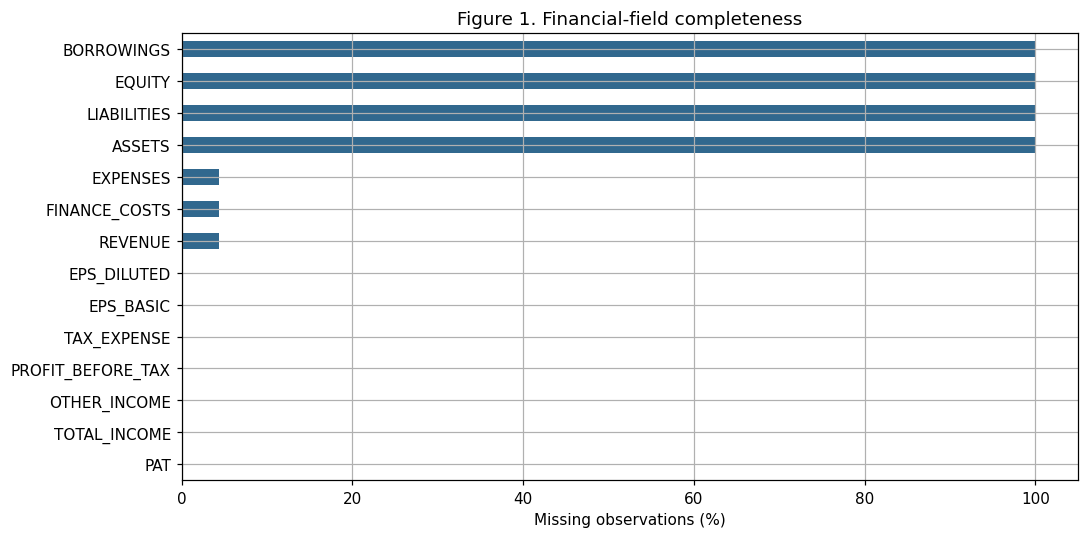

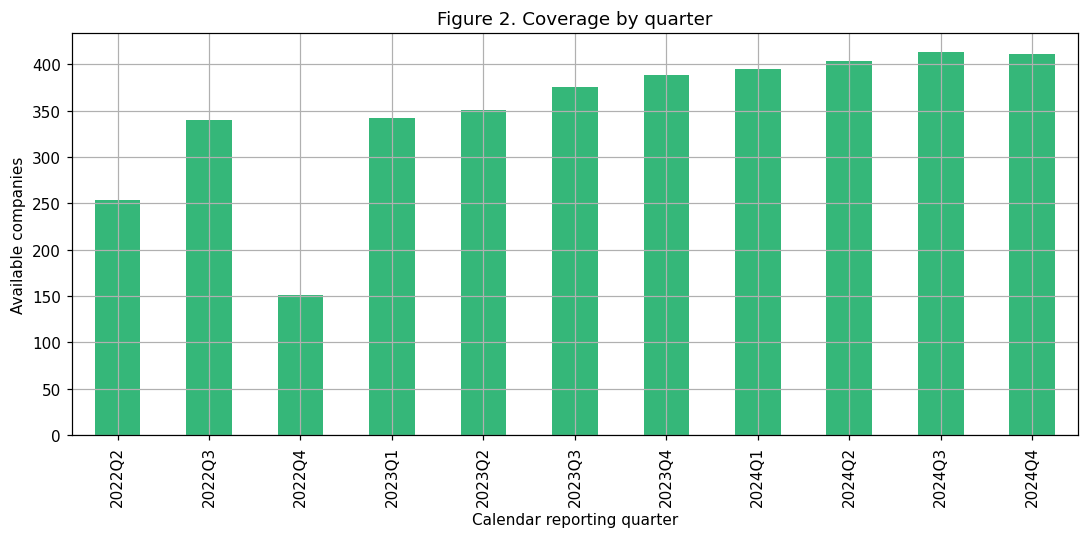

Complete across all observed quarters: 108


In [ ]:
missing = d[financial].isna().mean().sort_values()
fig, ax = plt.subplots()
(100*missing).plot.barh(ax=ax, color='#31688e')
ax.set(xlabel='Missing observations (%)', title='Figure 1. Financial-field completeness')
fig.tight_layout(); fig.savefig(OUTPUT/'figure1_missingness.png'); plt.show()
coverage = d.groupby('q').COMPANY_KEY.nunique()
fig, ax = plt.subplots()
coverage.plot.bar(ax=ax, color='#35b779')
ax.set(ylabel='Available companies', xlabel='Calendar reporting quarter', title='Figure 2. Coverage by quarter')
fig.tight_layout(); fig.savefig(OUTPUT/'figure2_coverage.png'); plt.show()
print('Complete across all observed quarters:', int((d.groupby('COMPANY_KEY').q.nunique()==d.q.nunique()).sum()))

## Feature engineering and consecutive-quarter target
Quarter labels are calendar quarters, not Indian fiscal-quarter labels. An exact company-quarter join prevents a missing quarter from being treated as the next quarter. Reported predictors use current-quarter values. Ratios require strictly positive denominators. Financial Services are retained as a separate industry, with sector diagnostics; revenue-based ratios are less comparable across financial and nonfinancial companies.

No generic operating-profit variable is fabricated from the banking-specific field. Sparse assets, equity and borrowings are omitted from the default model rather than synthesizing ROA/ROE/debt-to-equity from unsupported values.

In [ ]:
PAT_FLOOR = 0.0  # input monetary units; change only under a prespecified sensitivity protocol
lag = d[['COMPANY_KEY','q','PAT','REVENUE','EPS_BASIC']].copy()
lag['q'] = lag.q+1
lag = lag.rename(columns={c:c+'_lag1' for c in ['PAT','REVENUE','EPS_BASIC']})
d = d.merge(lag,on=['COMPANY_KEY','q'],how='left',validate='one_to_one')
future = d[['COMPANY_KEY','q','PAT']].copy()
future['q'] = future.q-1
future = future.rename(columns={'PAT':'PAT_next'})
d = d.merge(future,on=['COMPANY_KEY','q'],how='left',validate='one_to_one')
d['target_q'] = d.q+1
d['negative_base_pat'] = (d.PAT<0).astype(int)
d['target_growth_pct'] = 100*(d.PAT_next-d.PAT)/d.PAT.abs().where(d.PAT.abs()>PAT_FLOOR)
for col in ['PAT','REVENUE','EPS_BASIC']:
    denom = d[col+'_lag1'].abs().where(d[col+'_lag1'].abs()>0)
    d[col.lower()+'_growth_pct'] = 100*(d[col]-d[col+'_lag1'])/denom
d['pat_margin_pct'] = 100*d.PAT/d.REVENUE.where(d.REVENUE>0)
d['finance_cost_income_pct'] = 100*d.FINANCE_COSTS/d.TOTAL_INCOME.where(d.TOTAL_INCOME>0)
d['expense_income_pct'] = 100*d.EXPENSES/d.TOTAL_INCOME.where(d.TOTAL_INCOME>0)
d['quarter_of_year'] = d.PERIOD_END.dt.quarter.astype(str)
d.replace([np.inf,-np.inf],np.nan,inplace=True)
model = d.loc[d.target_growth_pct.notna()].copy()
print('Target-eligible observations:',len(model),'companies:',model.COMPANY_KEY.nunique())
print('No next-quarter PAT:', d.PAT_next.isna().sum(), 'zero/small base:', (d.PAT.abs()<=PAT_FLOOR).sum())
display(model.target_growth_pct.describe(percentiles=[.01,.05,.5,.95,.99]))
display(model.groupby('negative_base_pat').target_growth_pct.agg(['size','median','mean']))
dictionary_derived = {'target_growth_pct':'100*(PAT_next-PAT)/abs(PAT); exact next quarter; nonzero denominator',
 'pat_growth_pct':'100*(PAT-PAT_lag1)/abs(PAT_lag1); exact prior quarter',
 'revenue_growth_pct':'100*(REVENUE-REVENUE_lag1)/abs(REVENUE_lag1)',
 'eps_basic_growth_pct':'100*(EPS_BASIC-EPS_BASIC_lag1)/abs(EPS_BASIC_lag1)',
 'pat_margin_pct':'100*PAT/REVENUE, REVENUE>0',
 'finance_cost_income_pct':'100*FINANCE_COSTS/TOTAL_INCOME, TOTAL_INCOME>0',
 'expense_income_pct':'100*EXPENSES/TOTAL_INCOME, TOTAL_INCOME>0',
 'negative_base_pat':'1 if current PAT<0, else 0', 'quarter_of_year':'Calendar quarter categorical indicator'}
display(pd.Series(dictionary_derived,name='Definition'))
pd.Series(dictionary_derived).to_csv(OUTPUT/'derived_data_dictionary.csv')

Target-eligible observations: 3168 companies: 418
No next-quarter PAT: 654 zero/small base: 2


,target_growth_pct
count,3168.000000
mean,160.516477
std,2685.485456
min,-4223.076923
1%,-264.063657
5%,-87.610235
50%,4.586092
95%,256.544674
99%,2094.374777
max,119466.666667


,size,median,mean
negative_base_pat,,,
0,2975,3.795524,117.530174
1,193,60.398430,823.129177


,Definition
target_growth_pct,100*(PAT_next-PAT)/abs(PAT); exact next quarte...
pat_growth_pct,100*(PAT-PAT_lag1)/abs(PAT_lag1); exact prior ...
revenue_growth_pct,100*(REVENUE-REVENUE_lag1)/abs(REVENUE_lag1)
eps_basic_growth_pct,100*(EPS_BASIC-EPS_BASIC_lag1)/abs(EPS_BASIC_l...
pat_margin_pct,"100*PAT/REVENUE, REVENUE>0"
finance_cost_income_pct,"100*FINANCE_COSTS/TOTAL_INCOME, TOTAL_INCOME>0"
expense_income_pct,"100*EXPENSES/TOTAL_INCOME, TOTAL_INCOME>0"
negative_base_pat,"1 if current PAT<0, else 0"
quarter_of_year,Calendar quarter categorical indicator


## Exploratory statistics, patterns and anomalies
Means can be dominated by very small PAT denominators. Report medians, interquartile ranges and tail percentiles alongside means. Sector comparisons below are descriptive and unadjusted. Changes in quarterly coverage can change pooled aggregates even when underlying firms have not changed.

,variable,nonmissing,IQR_flags
0,PAT,3824,536
1,REVENUE,3659,484
2,TOTAL_INCOME,3824,507
3,pat_margin_pct,3653,330
4,pat_growth_pct,3168,485
5,target_growth_pct,3168,485


,INDEX_SYMBOL,q,PAT,PAT_next,target_growth_pct,SOURCE_XBRL_URL
1100,CHOLAHLDNG,2022Q4,3.000000e+05,3.587000e+08,119466.666667,https://nsearchives.nseindia.com/corporate/xbr...
3581,ASTERDM,2024Q1,-8.110000e+07,6.008240e+10,74184.340321,https://nsearchives.nseindia.com/corporate/xbr...
2042,PFOCUS,2024Q1,-8.616000e+06,2.210230e+09,25752.623027,https://nsearchives.nseindia.com/corporate/xbr...
3664,GLENMARK,2023Q4,-2.040900e+08,4.613695e+10,22706.178647,https://nsearchives.nseindia.com/corporate/xbr...
2086,BIOCON,2024Q3,3.200000e+07,5.840000e+09,18150.000000,https://nsearchives.nseindia.com/corporate/xbr...
2794,RPOWER,2023Q4,3.300000e+06,5.968000e+08,17984.848485,https://nsearchives.nseindia.com/corporate/xbr...
2952,ABCAPITAL,2023Q2,5.200000e+06,9.106000e+08,17411.538462,https://nsearchives.nseindia.com/corporate/xbr...
1361,VEDL,2023Q3,2.200000e+08,3.084000e+10,13918.181818,https://nsearchives.nseindia.com/corporate/xbr...
1350,IGL,2023Q2,4.384000e+07,5.348100e+09,12099.133212,https://nsearchives.nseindia.com/corporate/xbr...
1935,IRCTC,2022Q2,2.455239e+09,2.260306e+11,9106.052853,https://nsearchives.nseindia.com/corporate/xbr...


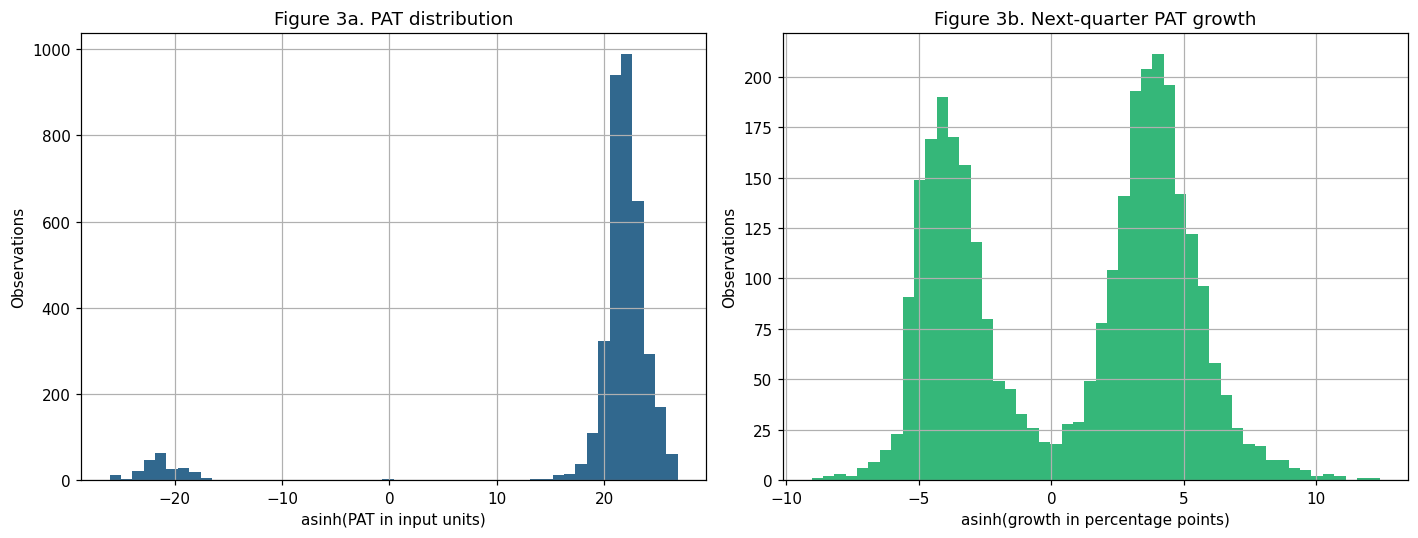

,n,companies,median_growth,median_margin
INDEX_INDUSTRY,,,,
Financial Services,517,80,5.128318,29.265721
Capital Goods,460,59,6.584247,10.305991
Healthcare,311,37,5.402010,16.835780
Automobile and Auto Components,285,36,3.353048,7.880374
Fast Moving Consumer Goods,199,27,6.714876,11.872977
Chemicals,183,23,6.250000,11.514019
Information Technology,138,20,2.594205,15.505131
Metals & Mining,124,15,-0.433994,8.756782
Power,119,15,1.345488,14.739852


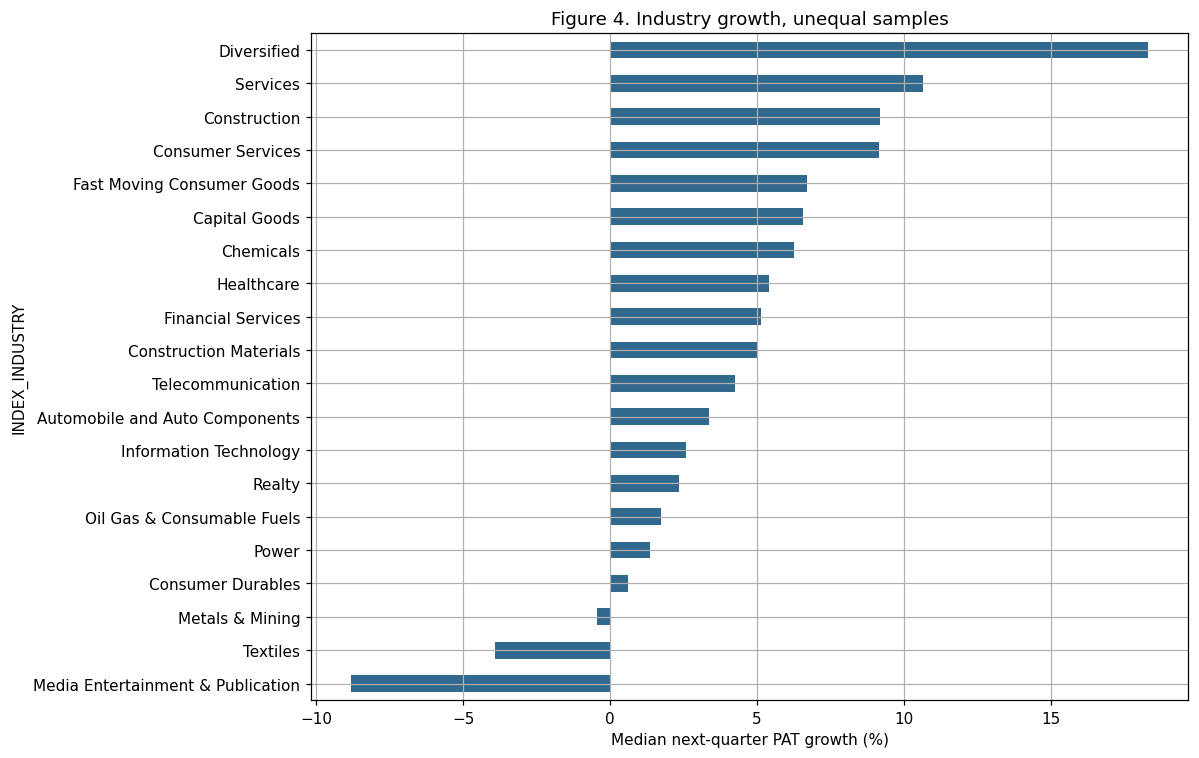

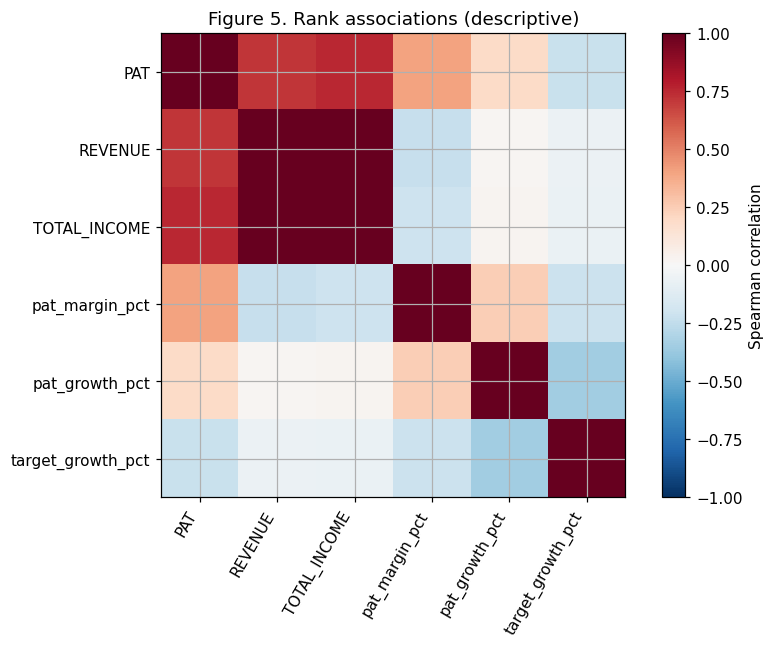

In [ ]:
eda_cols = ['PAT','REVENUE','TOTAL_INCOME','pat_margin_pct','pat_growth_pct','target_growth_pct']
outlier_rows=[]
for c in eda_cols:
    x=d[c].dropna(); q1,q3=x.quantile([.25,.75]); iqr=q3-q1
    outlier_rows.append([c,len(x),int(((x<q1-1.5*iqr)|(x>q3+1.5*iqr)).sum())])
display(pd.DataFrame(outlier_rows,columns=['variable','nonmissing','IQR_flags']))
display(model.nlargest(10,'target_growth_pct')[['INDEX_SYMBOL','q','PAT','PAT_next','target_growth_pct','SOURCE_XBRL_URL']])
fig, axes=plt.subplots(1,2,figsize=(13,5))
axes[0].hist(np.arcsinh(d.PAT.dropna()),bins=50,color='#31688e')
axes[0].set(title='Figure 3a. PAT distribution',xlabel='asinh(PAT in input units)',ylabel='Observations')
axes[1].hist(np.arcsinh(model.target_growth_pct),bins=50,color='#35b779')
axes[1].set(title='Figure 3b. Next-quarter PAT growth',xlabel='asinh(growth in percentage points)',ylabel='Observations')
fig.tight_layout(); fig.savefig(OUTPUT/'figure3_distributions.png'); plt.show()
sector=model.groupby('INDEX_INDUSTRY').agg(n=('target_growth_pct','size'),companies=('COMPANY_KEY','nunique'),median_growth=('target_growth_pct','median'),median_margin=('pat_margin_pct','median'))
display(sector.sort_values('n',ascending=False))
sector.to_csv(OUTPUT/'industry_summary.csv')
fig,ax=plt.subplots(figsize=(11,7))
sector.median_growth.sort_values().plot.barh(ax=ax,color='#31688e')
ax.set(xlabel='Median next-quarter PAT growth (%)',title='Figure 4. Industry growth, unequal samples')
fig.tight_layout(); fig.savefig(OUTPUT/'figure4_industry.png'); plt.show()
corr=model[eda_cols].corr(method='spearman')
fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(corr)),corr.columns,rotation=60,ha='right'); ax.set_yticks(range(len(corr)),corr.index)
fig.colorbar(im,ax=ax,label='Spearman correlation'); ax.set_title('Figure 5. Rank associations (descriptive)')
fig.tight_layout(); fig.savefig(OUTPUT/'figure5_correlation.png'); plt.show()

## Uncertainty and sample-size planning
For a descriptive uncertainty estimate, resample **companies**, retaining all each company's observations. The interval below estimates an equal-company mean of each firm's average PAT growth. It differs from the pooled company-quarter mean. Company resampling handles within-firm dependence but not common quarter shocks; with a short time window, intervals and significance claims require caution.

RQ1 uses a noncentral-F power calculation for a 15-predictor overall regression (alpha .05, power .80, f² .15). RQ2 uses a conservative normal approximation for one standardized coefficient (partial f² .15), Bonferroni alpha .05/15, with 16 degrees-of-freedom allowances. RQ3 uses four candidate model families: six pairwise comparisons, alpha .05/6, power .80, standardized paired-loss difference .30. RQ4 uses one prespecified paired comparison, alpha .05, power .80, d .30. These are independent-unit planning benchmarks, not proof that dependent panel rows meet the required power. Encoded feature counts and final hypotheses must replace these planning assumptions.

In [ ]:
company_mean=model.groupby('COMPANY_KEY').target_growth_pct.mean().dropna().to_numpy()
boot=np.array([rng.choice(company_mean,len(company_mean),replace=True).mean() for _ in range(2000)])
display(pd.Series({'company_count':len(company_mean),'equal_company_mean_growth_pct':company_mean.mean(),
                   'bootstrap_95_lower':np.quantile(boot,.025),'bootstrap_95_upper':np.quantile(boot,.975)}))
alpha=.05; power=.80; p=15; f2=.15
def regression_power(n):
    df2=n-p-1
    return stats.ncf.sf(stats.f.isf(alpha,p,df2),p,df2,f2*n)
n_reg=next(n for n in range(p+3,10000) if regression_power(n)>=power)
def paired_n(a,d=.30): return int(np.ceil(((stats.norm.ppf(1-a/2)+stats.norm.ppf(power))/d)**2))
n_coef=int(np.ceil(((stats.norm.ppf(1-alpha/(2*p))+stats.norm.ppf(power))/np.sqrt(f2))**2))+p+1
planning=pd.DataFrame({'RQ':['RQ1','RQ2','RQ3','RQ4'],
 'method':['Overall regression noncentral F','Coefficient normal approximation + df allowance','Paired-loss normal approximation, 6 comparisons','Paired-loss normal approximation'],
 'independent_units_required':[n_reg,n_coef,paired_n(.05/6),paired_n(.05)]})
display(planning); planning.to_csv(OUTPUT/'sample_size_planning.csv',index=False)
print('These counts cannot be compared directly with panel rows as if all rows were independent.')

,0
company_count,418.000000
equal_company_mean_growth_pct,145.046432
bootstrap_95_lower,78.656450
bootstrap_95_upper,236.496259


,RQ,method,independent_units_required
0,RQ1,Overall regression noncentral F,139
1,RQ2,Coefficient normal approximation + df allowance,112
2,RQ3,"Paired-loss normal approximation, 6 comparisons",135
3,RQ4,Paired-loss normal approximation,88


These counts cannot be compared directly with panel rows as if all rows were independent.


## Chronological modeling and leakage controls
Split by **target quarter**, keeping every company in the same quarter partition. Last two target quarters form the test period, preceding two validation, earlier quarters training. Imputation, feature inclusion thresholds, encoding and scaling are learned from training only. Validation selects the best enhanced model; test is used for one descriptive comparison after selection. No tuning follows test results.

Critical limitation: quarter-end ordering alone cannot establish real-time information availability. This extract lacks a standardized filing-availability timestamp and restatement history. Results therefore evaluate retrospective forecasting conditional on current-quarter data being known. A deployment-quality study must apply filing-date cutoffs and an embargo based on actual availability.

Linear regression supplies an interpretable reference but is vulnerable to collinearity and heavy tails. Ridge regularizes correlated features. Random forest and gradient boosting allow nonlinearities. Simple baselines determine whether complexity helps. The notebook uses scikit-learn gradient boosting rather than claiming XGBoost or LightGBM were run.

In [ ]:
quarters=sorted(model.target_q.unique())
assert len(quarters)>=7
train=model[model.target_q.isin(quarters[:-4])].copy()
valid=model[model.target_q.isin(quarters[-4:-2])].copy()
test=model[model.target_q.isin(quarters[-2:])].copy()
display(pd.DataFrame([{'split':name,'n':len(z),'companies':z.COMPANY_KEY.nunique(),
 'target_start':str(z.target_q.min()),'target_end':str(z.target_q.max())}
 for name,z in [('train',train),('validation',valid),('test',test)]]))
reported=[c for c in financial if train[c].notna().mean()>=.50]
derived=['pat_growth_pct','revenue_growth_pct','eps_basic_growth_pct','pat_margin_pct',
         'finance_cost_income_pct','expense_income_pct','negative_base_pat']
enhanced=reported+[c for c in derived if train[c].notna().mean()>=.50]
cat=['INDEX_INDUSTRY','quarter_of_year']
print('Reported features:',reported); print('Enhanced features:',enhanced)
def pipe(estimator,nums):
    prep=ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())]),nums),
        ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])
    return Pipeline([('preprocess',prep),('model',estimator)])
def metrics(y,pred):
    return {'MAE_pp':mean_absolute_error(y,pred),'RMSE_pp':np.sqrt(mean_squared_error(y,pred)),'R2':r2_score(y,pred)}
estimators={'Linear':LinearRegression(),'Ridge':Ridge(alpha=10),
 'Random forest':RandomForestRegressor(n_estimators=150,min_samples_leaf=10,max_features=.8,random_state=SEED,n_jobs=-1),
 'Gradient boosting':GradientBoostingRegressor(n_estimators=100,max_depth=2,min_samples_leaf=15,random_state=SEED)}
fitted={}; val_results=[]
for name,est in estimators.items():
    fitted[name]=pipe(est,enhanced).fit(train,train.target_growth_pct)
    val_results.append({'model':name,**metrics(valid.target_growth_pct,fitted[name].predict(valid))})
validation_scores=pd.DataFrame(val_results).sort_values('MAE_pp')
display(validation_scores)
selected=validation_scores.iloc[0]['model']
print('Selected on validation MAE:',selected)
importance=permutation_importance(fitted[selected],valid[enhanced+cat],valid.target_growth_pct,
 scoring='neg_mean_absolute_error',n_repeats=5,random_state=SEED)
importance_table=pd.DataFrame({'feature':enhanced+cat,'importance_MAE_pp':importance.importances_mean,
                              'repeat_std':importance.importances_std}).sort_values('importance_MAE_pp',ascending=False)
display(importance_table[importance_table.feature.isin(enhanced+cat)].head(15))
importance_table.to_csv(OUTPUT/'validation_permutation_importance.csv',index=False)

,split,n,companies,target_start,target_end
0,train,1593,381,2022Q3,2023Q4
1,validation,777,395,2024Q1,2024Q2
2,test,798,413,2024Q3,2024Q4


Reported features: ['PAT', 'REVENUE', 'TOTAL_INCOME', 'OTHER_INCOME', 'PROFIT_BEFORE_TAX', 'TAX_EXPENSE', 'EXPENSES', 'FINANCE_COSTS', 'EPS_BASIC', 'EPS_DILUTED']
Enhanced features: ['PAT', 'REVENUE', 'TOTAL_INCOME', 'OTHER_INCOME', 'PROFIT_BEFORE_TAX', 'TAX_EXPENSE', 'EXPENSES', 'FINANCE_COSTS', 'EPS_BASIC', 'EPS_DILUTED', 'pat_growth_pct', 'revenue_growth_pct', 'eps_basic_growth_pct', 'pat_margin_pct', 'finance_cost_income_pct', 'expense_income_pct', 'negative_base_pat']


,model,MAE_pp,RMSE_pp,R2
2,Random forest,360.583813,2970.753863,0.039773
3,Gradient boosting,392.943985,3099.690794,-0.045388
1,Ridge,791.706338,3121.329821,-0.060035
0,Linear,817.478131,3130.915606,-0.066556


Selected on validation MAE: Random forest


,feature,importance_MAE_pp,repeat_std
10,pat_growth_pct,62.885670,2.022682
8,EPS_BASIC,17.571394,0.932804
11,revenue_growth_pct,17.452229,0.443331
13,pat_margin_pct,13.464098,1.036455
15,expense_income_pct,10.800358,1.114448
12,eps_basic_growth_pct,10.492387,0.725764
2,TOTAL_INCOME,7.301528,1.620807
6,EXPENSES,6.745543,0.988375
4,PROFIT_BEFORE_TAX,5.070563,0.597010
9,EPS_DILUTED,4.971245,0.588949


,model,MAE_pp,RMSE_pp,R2
0,Zero growth,126.708358,790.271274,-0.012792
1,Historical median,126.348072,789.735668,-0.011419
2,Linear,341.483132,887.389812,-0.277017
3,Ridge,328.845810,880.117110,-0.256171
4,Random forest,232.778001,1045.715154,-0.773351
5,Gradient boosting,259.848600,1179.052378,-1.254416
6,Ridge reported only,278.251215,820.881491,-0.092770


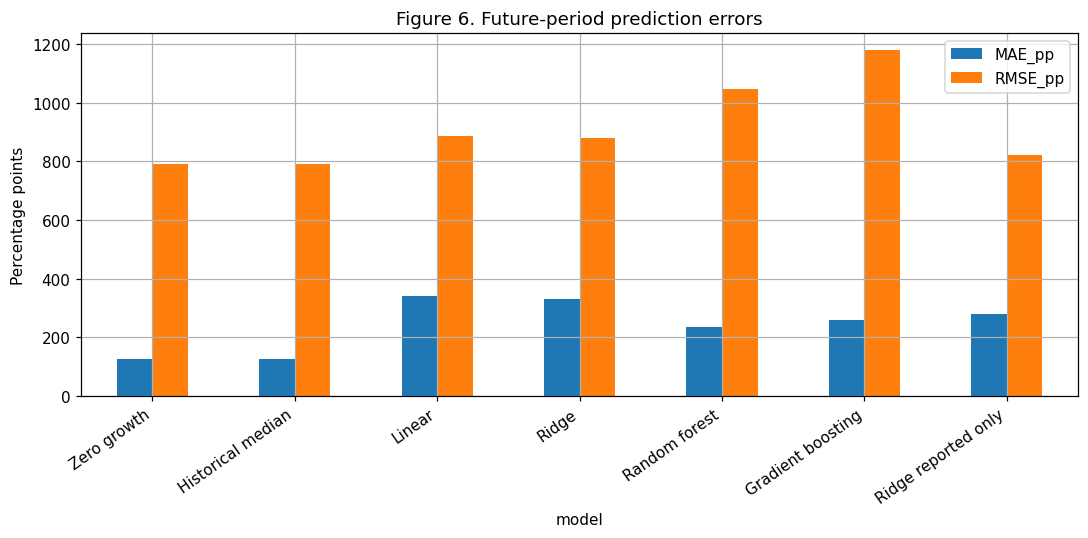

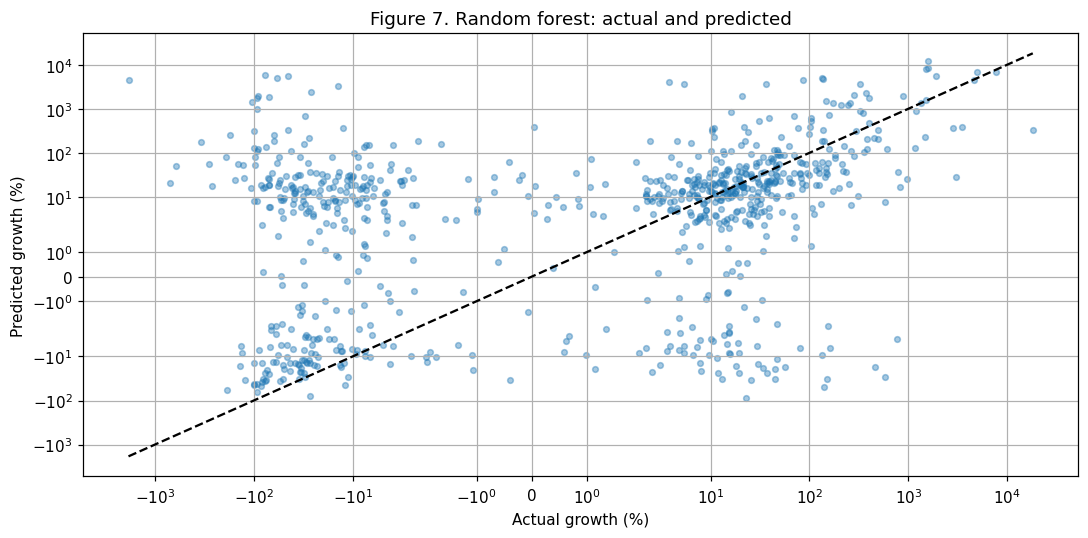

,size,mean,median
INDEX_INDUSTRY,,,
Automobile and Auto Components,69,73.493368,18.349570
Capital Goods,106,164.123153,19.930033
Chemicals,46,137.265507,23.421346
Construction,23,154.151171,20.758660
Construction Materials,16,352.250399,161.241416
Consumer Durables,28,211.525668,54.821161
Consumer Services,29,377.688303,184.327305
Diversified,2,81.597867,81.597867
Fast Moving Consumer Goods,54,142.401588,16.093581


,size,mean,median
negative_base_pat,,,
0,755,183.268905,23.212476
1,43,1102.065614,423.961303


In [ ]:
# Fixed model choices now refit on training + validation. No further tuning.
from sklearn.base import clone
development=pd.concat([train,valid],ignore_index=True)
predictions={'Zero growth':np.zeros(len(test)),
             'Historical median':np.full(len(test),train.target_growth_pct.median())}
final_models={}
for name,prototype in fitted.items():
    final_models[name]=clone(prototype).fit(development,development.target_growth_pct)
    predictions[name]=final_models[name].predict(test)
reported_ridge=pipe(Ridge(alpha=10),reported).fit(development,development.target_growth_pct)
predictions['Ridge reported only']=reported_ridge.predict(test)
scores=pd.DataFrame([{'model':name,**metrics(test.target_growth_pct,pred)} for name,pred in predictions.items()])
display(scores)
scores.to_csv(OUTPUT/'test_metrics.csv',index=False)
prediction_export=test[['COMPANY_KEY','INDEX_SYMBOL','INDEX_INDUSTRY','q','target_q','target_growth_pct','negative_base_pat']].copy()
for name,pred in predictions.items(): prediction_export[name]=pred
prediction_export.to_csv(OUTPUT/'test_predictions.csv',index=False)
fig,ax=plt.subplots()
scores.set_index('model')[['MAE_pp','RMSE_pp']].plot.bar(ax=ax)
ax.set(ylabel='Percentage points',title='Figure 6. Future-period prediction errors')
plt.xticks(rotation=35,ha='right'); fig.tight_layout(); fig.savefig(OUTPUT/'figure6_model_errors.png'); plt.show()
pred=predictions[selected]
fig,ax=plt.subplots(); ax.scatter(test.target_growth_pct,pred,alpha=.4,s=14)
limits=[min(test.target_growth_pct.min(),pred.min()),max(test.target_growth_pct.max(),pred.max())]
ax.plot(limits,limits,'k--'); ax.set(xlabel='Actual growth (%)',ylabel='Predicted growth (%)',title=f'Figure 7. {selected}: actual and predicted')
ax.set_xscale('symlog'); ax.set_yscale('symlog'); fig.tight_layout(); fig.savefig(OUTPUT/'figure7_predictions.png'); plt.show()
diagnostic=test[['INDEX_INDUSTRY','negative_base_pat']].copy()
diagnostic['absolute_error']=np.abs(test.target_growth_pct.to_numpy()-pred)
display(diagnostic.groupby('INDEX_INDUSTRY').absolute_error.agg(['size','mean','median']))
display(diagnostic.groupby('negative_base_pat').absolute_error.agg(['size','mean','median']))

## Paired feature-set comparison and research-question conclusions
Compare absolute errors on identical test observations. Resample company-average paired loss differences. A positive difference means the enhanced ridge has lower error. This company bootstrap does not account for shared quarter shocks and is not a final confirmatory hypothesis test. RMSE differences alone are not evidence of statistical significance.

In [ ]:
loss_base=np.abs(test.target_growth_pct.to_numpy()-predictions['Ridge reported only'])
loss_enh=np.abs(test.target_growth_pct.to_numpy()-predictions['Ridge'])
paired=pd.DataFrame({'company':test.COMPANY_KEY.to_numpy(),'improvement':loss_base-loss_enh})
firm_delta=paired.groupby('company').improvement.mean().to_numpy()
delta_boot=np.array([rng.choice(firm_delta,len(firm_delta),replace=True).mean() for _ in range(2000)])
display(pd.Series({'paired_rows':len(paired),'paired_companies':len(firm_delta),
 'pooled_MAE_improvement_pp':paired.improvement.mean(),
 'equal_company_improvement_pp':firm_delta.mean(),
 'company_bootstrap_lower':np.quantile(delta_boot,.025),'company_bootstrap_upper':np.quantile(delta_boot,.975)}))
best=scores.set_index('model').loc[selected]
baseline=scores.set_index('model').loc['Historical median']
display(Markdown(f'''### Evidence for the interim report
- **RQ1:** Validation-selected {selected} achieved test MAE **{best.MAE_pp:.2f} pp**, versus **{baseline.MAE_pp:.2f} pp** for the historical-median baseline. Predictive usefulness must be judged against this baseline and tail sensitivity. No overall-regression significance claim is made.
- **RQ2:** The validation importance table identifies predictive contributions conditional on this model and feature set. Correlated features can share importance. Coefficient inference remains pending.
- **RQ3:** The model was selected by validation MAE, not by selecting the best test score. The test table gives the prespecified comparison; additional periods are needed to assess stability.
- **RQ4:** Enhanced ridge minus reported-only comparison produced a pooled MAE improvement of **{paired.improvement.mean():.2f} pp**. Positive values favor engineered features. The company-bootstrap interval above is exploratory.
'''))
d.to_csv(OUTPUT/'cleaned_features_and_targets.csv',index=False)
print('Analysis tables, figures, provenance and cleaned data saved to:',OUTPUT.resolve())

,0
paired_rows,798.000000
paired_companies,413.000000
pooled_MAE_improvement_pp,-50.594595
equal_company_improvement_pp,-54.144197
company_bootstrap_lower,-79.145167
company_bootstrap_upper,-33.043303


### Evidence for the interim report
- **RQ1:** Validation-selected Random forest achieved test MAE **232.78 pp**, versus **126.35 pp** for the historical-median baseline. Predictive usefulness must be judged against this baseline and tail sensitivity. No overall-regression significance claim is made.
- **RQ2:** The validation importance table identifies predictive contributions conditional on this model and feature set. Correlated features can share importance. Coefficient inference remains pending.
- **RQ3:** The model was selected by validation MAE, not by selecting the best test score. The test table gives the prespecified comparison; additional periods are needed to assess stability.
- **RQ4:** Enhanced ridge minus reported-only comparison produced a pooled MAE improvement of **-50.59 pp**. Positive values favor engineered features. The company-bootstrap interval above is exploratory.


Analysis tables, figures, provenance and cleaned data saved to: /content/analysis_outputs


## Limitations and next steps for mentor review
- This is an available-case Nifty 500 extract, not a random sample of the total listed universe. Confirm constituent snapshot date and explain 74 absent companies relative to a nominal universe of 500.
- The short, unbalanced panel limits temporal generalization. Results are conditional on sector representation and available filings. Repeat analysis with a balanced-company sensitivity cohort.
- Validate normalized units, PAT tags, restatements, sector comparability, rounding and exceptional/discontinued items against original filings. PBT minus tax need not equal total PAT where definitions differ.
- Finalize a small-PAT denominator rule before model selection. Report negative-base and positive-base results separately. Do not remove extreme outcomes merely to improve scores.
- Add audited filing-availability timestamps, rolling evaluation by complete quarters, an appropriate availability embargo, seasonal PAT-growth baselines where enough history exists, and dependence-aware inference.
- RQ1/RQ2 confirmatory regression requires a specified estimand, collinearity diagnostics, residual checks, clustered covariance and joint/predictor tests. Current feature importance does not fulfill these tests.
- Recompute sample-size planning for the final encoded specification and chosen model comparisons. Panel dependence and only a few test quarters prevent treating thousands of rows as independent evidence.
- Add a literature synthesis comparing the synopsis's forecasting papers after independently verifying their bibliographic details. Documentation references below support workflow methods, not a complete academic literature review.

## Interim-report assembly checklist
Use the institution's actual template, title page, consistent APA headings, double spacing, 1-inch margins, page numbers and labeled figures/tables. Include revised scope, RQ1–RQ4, data provenance, both dictionaries, cleaning audit, sample-size assumptions, figures, metrics, limitations and mentor feedback. The report requires a PDF; the notebook is a supporting analytical artifact. The synopsis lists the repository as https://github.com/puneet1983/QM640_Data_Analytics/tree/main/nse-financial-research (user-provided reference; publication state not verified here). Do not invent screenshots, extraction dates or completed analyses.

## Method references
National Stock Exchange of India. (n.d.). *Corporate filings: Financial results*. https://www.nseindia.com/companies-listing/corporate-filings-financial-results  
National Institute of Standards and Technology. (n.d.). *Confidence limits for the mean*. https://itl.nist.gov/div898/handbook/eda/section3/eda352.htm  
National Institute of Standards and Technology. (n.d.). *Sample sizes required*. https://www.itl.nist.gov/div898/handbook/prc/section2/prc222.htm  
Scikit-learn developers. (n.d.). *TimeSeriesSplit*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html

NSE supplies the filing context; per-row `SOURCE_XBRL_URL` retains exact provenance. NIST describes mean confidence intervals and precision planning; the company bootstrap is a panel adaptation described above. Scikit-learn explains the rationale for time ordering; this notebook groups complete target quarters rather than splitting individual panel rows with TimeSeriesSplit.